# Paired trajectory sensitivity analysis
Compares the primary mixed-effects specification with a trajectory-matched paired-difference regression using team-location clustered standard errors. The latter explicitly pairs scenarios within each trajectory and allows arbitrary dependence within each team-location cluster. It is a sensitivity analysis, **not** a trajectory-level mixed-effects model. Done with the help of ChatGPT 6

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from IPython.display import display
DATA = Path('outbreak_magnitudes_summary.csv')
POP = Path('locations_pop.csv')
OUT = Path('paired_sensitivity_results'); OUT.mkdir(exist_ok=True)
REF = 'A-2025-04-01'
KEY = ['team','location','output_type_index']
OUTCOMES = {'total':'total_per_100k','summer':'summer_per_100k','winter':'winter_per_100k'}


/Users/anjalikanande/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
df = pd.read_csv(DATA, dtype={'location':str})
pop = pd.read_csv(POP, dtype={'location':str})
assert not pop.location.duplicated().any()
df = df.merge(pop[['location','population']], on='location', validate='many_to_one')
assert df.population.notna().all() and (df.population > 0).all()
df['summer_per_100k'] = df.first_half / df.population * 1e5
df['winter_per_100k'] = df.second_half / df.population * 1e5
df['total_per_100k'] = df.summer_per_100k + df.winter_per_100k
assert not df.duplicated(KEY+['scenario_id']).any(), 'Duplicate trajectory-scenario keys'
scenarios = sorted(df.scenario_id.unique()); assert REF in scenarios
coverage = df.groupby(KEY).scenario_id.nunique()
print('Rows:',len(df),'Unique trajectories:',len(coverage),'Scenario coverage:',coverage.value_counts().to_dict())
assert (coverage == len(scenarios)).all(), 'Some trajectories have incomplete scenario coverage'
df['scenario_id'] = pd.Categorical(df.scenario_id,categories=[REF]+[s for s in scenarios if s!=REF])
df['team_location'] = df.team.astype(str)+'::'+df.location.astype(str)


Rows: 413740 Unique trajectories: 82748 Scenario coverage: {5: 82748}


## 1. Primary mixed-effects model
Matches the original specification: location random intercept and team-within-location variance component.

In [3]:
RUN_PRIMARY = True
primary_results=[]
if RUN_PRIMARY:
    for label, outcome in OUTCOMES.items():
        print('Fitting primary:',label,flush=True)
        model=smf.mixedlm(f'{outcome} ~ C(scenario_id, Treatment(reference="{REF}"))', data=df,
                          groups=df.location, re_formula='1',vc_formula={'team':'0 + C(team)'})
        fit=model.fit(method='powell', reml=True)
        for term in fit.fe_params.index:
            if 'scenario_id' not in term: continue
            scenario=term.split('[T.')[-1].rstrip(']')
            primary_results.append(dict(outcome=label,scenario=scenario,method='primary mixed model',
                                        averted_per_100k=-fit.fe_params[term],se=fit.bse_fe[term],converged=fit.converged))
    pd.DataFrame(primary_results).to_csv(OUT/'primary_results.csv',index=False)
else:
    p=OUT/'primary_results.csv'
    if p.exists(): primary_results=pd.read_csv(p).to_dict('records')

Fitting primary: total
Fitting primary: summer
Fitting primary: winter


/Users/anjalikanande/anaconda3/lib/python3.10/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)


## 2. Trajectory-matched sensitivity analysis
Within each team–location–`output_type_index`, subtract each vaccinated-scenario outcome from Scenario A. Fit scenario-specific mean differences without an intercept. Cluster-robust standard errors are computed at the **team–location** level, accommodating correlation across scenarios and trajectories within a team–location. This is conservative relative to clustering only by trajectory but does not model arbitrary dependence across locations from the same team. 

In [4]:
paired_results=[]
for label,outcome in OUTCOMES.items():
    wide=df.pivot(index=KEY,columns='scenario_id',values=outcome)
    assert not wide.isna().any().any()
    diff=wide.drop(columns=[REF]).rsub(wide[REF],axis=0)
    long=diff.stack(future_stack=True).rename('averted_per_100k').reset_index()
    long=long[long.scenario_id != REF].copy()
    long['scenario_id']=long['scenario_id'].cat.remove_unused_categories()
    long['team_location']=long.team.astype(str)+'::'+long.location.astype(str)
    fit=smf.ols('averted_per_100k ~ 0 + C(scenario_id)',data=long).fit(
        cov_type='cluster',cov_kwds={'groups':long.team_location},use_t=True)
    print(label,'paired observations:',len(long),'clusters:',long.team_location.nunique())
    for term in fit.params.index:
        scenario=term.split('[')[-1].rstrip(']')
        paired_results.append(dict(outcome=label,scenario=scenario,method='paired differences (team-location clustered)',
                                   averted_per_100k=fit.params[term],se=fit.bse[term],converged=True,
                                   ci_low=fit.conf_int().loc[term,0],ci_high=fit.conf_int().loc[term,1]))
paired=pd.DataFrame(paired_results)
paired.to_csv(OUT/'paired_results.csv',index=False)
display(paired.round(3))

total paired observations: 330992 clusters: 414
summer paired observations: 330992 clusters: 414
winter paired observations: 330992 clusters: 414


,outcome,scenario,method,averted_per_100k,se,converged,ci_low,ci_high
0,total,B-2025-04-01,paired differences (team-location clustered),30.091,1.072,True,27.984,32.197
1,total,C-2025-04-01,paired differences (team-location clustered),33.750,1.191,True,31.409,36.091
2,total,D-2025-04-01,paired differences (team-location clustered),38.244,1.454,True,35.385,41.103
3,total,E-2025-04-01,paired differences (team-location clustered),43.045,1.652,True,39.798,46.292
4,summer,B-2025-04-01,paired differences (team-location clustered),3.730,0.164,True,3.409,4.052
5,summer,C-2025-04-01,paired differences (team-location clustered),9.029,0.373,True,8.296,9.761
6,summer,D-2025-04-01,paired differences (team-location clustered),4.365,0.197,True,3.978,4.753
7,summer,E-2025-04-01,paired differences (team-location clustered),11.212,0.485,True,10.259,12.164
8,winter,B-2025-04-01,paired differences (team-location clustered),26.360,1.087,True,24.224,28.497
9,winter,C-2025-04-01,paired differences (team-location clustered),24.721,1.147,True,22.467,26.975


## 3. Compare primary and paired estimates

,outcome,scenario,method,averted_per_100k,se,converged,ci_low,ci_high
0,total,B-2025-04-01,primary mixed model,30.091,0.288,True,29.526,30.655
1,total,C-2025-04-01,primary mixed model,33.750,0.288,True,33.185,34.314
2,total,D-2025-04-01,primary mixed model,38.244,0.288,True,37.679,38.808
3,total,E-2025-04-01,primary mixed model,43.045,0.288,True,42.481,43.610
4,summer,B-2025-04-01,primary mixed model,3.730,0.178,True,3.382,4.078
5,summer,C-2025-04-01,primary mixed model,9.029,0.178,True,8.680,9.377
6,summer,D-2025-04-01,primary mixed model,4.365,0.178,True,4.017,4.713
7,summer,E-2025-04-01,primary mixed model,11.212,0.178,True,10.864,11.560
8,winter,B-2025-04-01,primary mixed model,26.360,0.217,True,25.934,26.787
9,winter,C-2025-04-01,primary mixed model,24.721,0.217,True,24.295,25.147


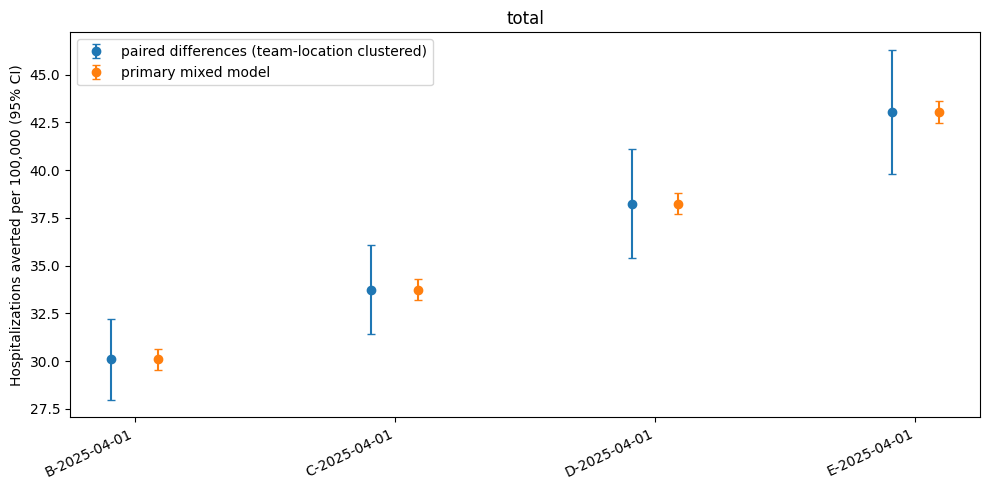

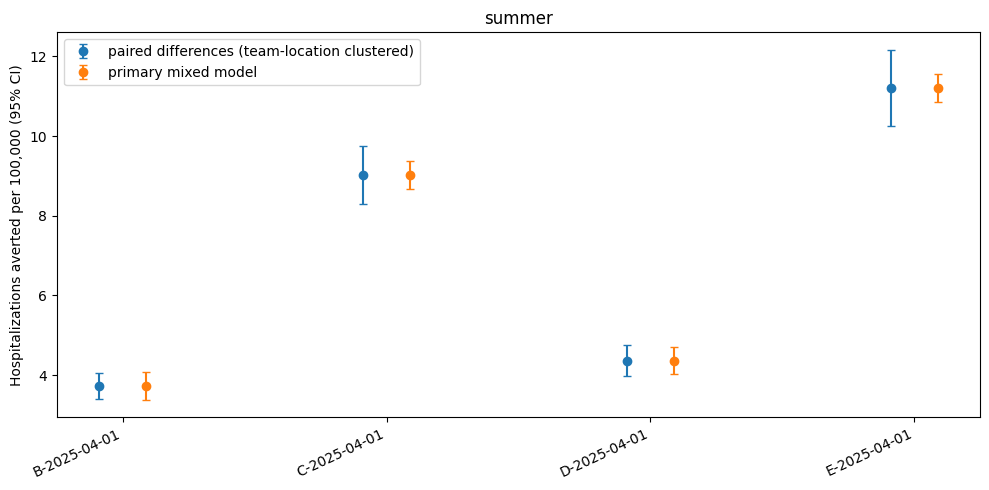

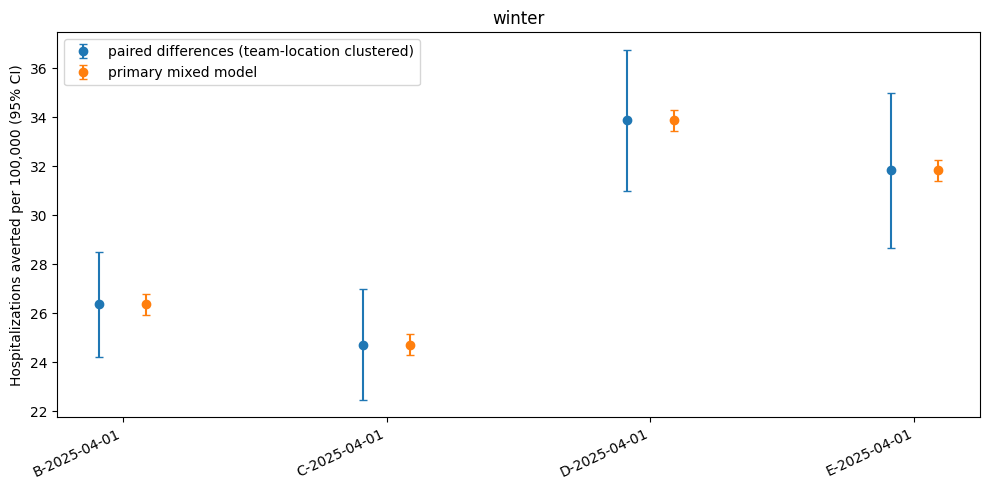

In [6]:
all_results=pd.concat([pd.DataFrame(primary_results),paired],ignore_index=True)
if all_results.empty: raise RuntimeError('No results')
all_results['ci_low']=all_results['ci_low'].fillna(all_results.averted_per_100k-1.96*all_results.se) if 'ci_low' in all_results else all_results.averted_per_100k-1.96*all_results.se
all_results['ci_high']=all_results['ci_high'].fillna(all_results.averted_per_100k+1.96*all_results.se) if 'ci_high' in all_results else all_results.averted_per_100k+1.96*all_results.se
all_results.to_csv(OUT/'primary_vs_paired_estimates.csv',index=False)
display(all_results.round(3))
if len(primary_results):
    p=all_results.pivot(index=['outcome','scenario'],columns='method',values=['averted_per_100k','se'])
    p.to_csv(OUT/'primary_vs_paired_wide.csv')
    for label in OUTCOMES:
        sub=all_results[all_results.outcome==label]
        fig,ax=plt.subplots(figsize=(10,5))
        for i,(method,group) in enumerate(sub.groupby('method')):
            group=group.sort_values('scenario'); x=np.arange(len(group))+(i-.5)*.18
            ax.errorbar(x,group.averted_per_100k,yerr=[group.averted_per_100k-group.ci_low,group.ci_high-group.averted_per_100k],fmt='o',capsize=3,label=method)
        ax.set_xticks(np.arange(len(group)),group.scenario,rotation=25,ha='right')
        ax.set_ylabel('Hospitalizations averted per 100,000 (95% CI)');ax.set_title(label);ax.legend();fig.tight_layout()
        fig.savefig(OUT/f'comparison_{label}.pdf',dpi=150);plt.show()
